# DATA-445: Homework Assignment 7

**Instructions**

- This homework assignment is worth **103** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**:
  - AI use is strictly **prohibited** for conceptual exercises.
  - For applied (Python) exercises, you may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 6, 2026, by 11:59 PM.**

## Exercise 1 (5 points)

Why feature scaling is important for the $k$-means algorithm? Be specific.

Because the k means algorithm relies on metrics like the euclidean distance the features with largers numbers will influence the calculations and could cause misleading results. When you dont scale your data the cluster centroids and decision boundaries become biased towards the high magnitude features and looks over the patterns in the smaller scaled variables. 

## Exercise 2 (5 points)

How can clustering be used to improve the performance of a linear model?

(a) Creating different models for different cluster groups.

(b) Creating an input feature for cluster ids as dummy variables.

(c) Creating an input feature for cluster centroids as a continuous variable.

(d) Creating an input feature for cluster size as a continuous variable.

(e) All of the above.

(f) None of the above.

(a)

## Exercise 3 (5 points)

What are the risks of initial random cluster centroids assignments in $k$-means? Be specific.

The initial random centroid assignments can trap k means into creating poor inconsistent clusters or even groups that are empty. It also makes the algorithm take more steps and time to finish running.

## Exercise 4 (5 points)

Spectral clustering and $k$-means make different assumptions about the shape of the clusters. Explain, in your own words, how spectral clustering constructs clusters (mention the similarity graph and the graph Laplacian) and describe a type of dataset for which spectral clustering would be expected to outperform $k$-means. Be specific.

Spectral clustering creates a similarity network of neighboring points and then calculates a graph Laplacian to see the data shapes. This allows it to easily seperate complex datasets like nested rings or half moons where standard k means fails. 

## Exercise 5 (5 points)

In $k$-means, every observation is assigned to exactly one cluster (a hard assignment). Explain how fuzzy c-means differs from $k$-means in terms of cluster membership, and describe what role the fuzziness parameter $m$ plays in the algorithm. Be specific.

k means forces every data point into a single cluster whereas fuzzy c means gives each point a membership score between 0 and 1 for every cluster. The fuzziness parameter m controls how much these clusters overlap which allows for smooth boundaries instead of the hard cut offs. 

## Exercise 6

Consider the `Mall_Customers.csv` data file. This file contains the basic information (ID, age, gender, income, spending score) about mall customers in the US. **In Python**, answer the following:

### (a) (5 points)

Using the `pandas` library, read the csv data file and create a data-frame called `customers`. Remove the observations with missing values (if there are missing values).

In [10]:
import pandas as pd

customers = pd.read_csv('Mall_Customers.csv')

customers.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
customers.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

### (b) (8 points)

Using the appropriate Python commands, put `Gender`, `Age` and `Annual Income (k$)` in the same scale.

In [12]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

customers["Gender"] = customers["Gender"].map({"Male": 0, "Female": 1})

customers[["Gender", "Age", "Annual Income (k$)"]] = scaler.fit_transform(customers[["Gender", "Age", "Annual Income (k$)"]])
customers.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0.0,0.019231,0.000000,39
1,2,0.0,0.057692,0.000000,81
2,3,1.0,0.038462,0.008197,6
3,4,1.0,0.096154,0.008197,77
4,5,1.0,0.250000,0.016393,40


### (c) (30 points)

Because you are not familiar enough with buying patterns in malls, estimate the number of clusters for this dataset using the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores. Do the following:

- Using `Gender`, `Age` and `Annual Income (k$)` cluster that data into clusters ($k = 2, 3, \ldots, 9, 10$). Use `n_init = 20`.
- For each clustering result, compute the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores.
- Visualize the Calinski-Harabasz, Davies-Bouldin, and Silhouette scores.
- Estimate the number of clusters.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (calinski_harabasz_score,
                             davies_bouldin_score,
                             silhouette_score)

features = ['Gender', 'Age', 'Annual Income (k$)']

components_scaled = customers[features]

kmeans = KMeans(n_clusters=4, n_init=20, random_state=42)
labels = kmeans.fit_predict(components_scaled)

print("Calinski-Harabasz:", calinski_harabasz_score(components_scaled, labels))
print("Davies-Bouldin:   ", davies_bouldin_score(components_scaled, labels))
print("Silhouette:       ", silhouette_score(components_scaled, labels))





Calinski-Harabasz: 307.20770951203195
Davies-Bouldin:    0.9265113681046688
Silhouette:        0.41620738097166066


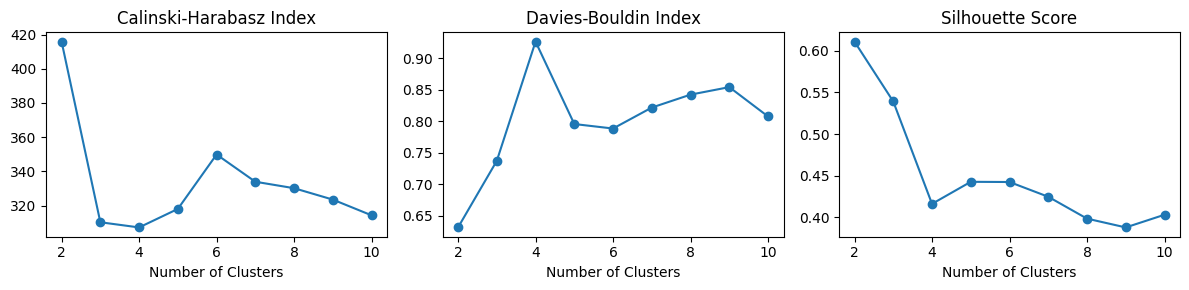

In [24]:
# Visualize

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, col in zip (axes, scores.columns):
    ax.plot(scores.index, scores[col], marker='o')
    ax.set_title(col)
    ax.set_xlabel('Number of Clusters')

plt.tight_layout()
plt.show()

All three scores point to k = 2

### (d) (8 points)

Using the results from part (c), cluster the data into that number of clusters (use `n_init = 20`).

In [27]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
customers["Cluster"] = kmeans.fit_predict(customers[features])

print(customers["Cluster"].value_counts().sort_index())

print(pd.crosstab(customers["Cluster"], customers["Gender"]))
print(customers.groupby("Cluster")[features].mean())

Cluster
0     88
1    112
Name: count, dtype: int64
Gender   0.0  1.0
Cluster          
0         88    0
1          0  112
         Gender       Age  Annual Income (k$)
Cluster                                      
0           0.0  0.419362            0.387109
1           1.0  0.386504            0.362705


### (e) (7 points)

Describe each of the clusters. Does the clustering results make sense? If not, suggest how you would improve this analysis.

Cluster 0 (88 customers) is all male with average age about 40 and an annual income of about 62k (0.387109 × (137 − 15) + 15 = 62.2). Cluster 1 (112 customers) is all female with an average age of 38 and an income of about 59k (0.362705 × (137 − 15) + 15 = 59.3). They dont make a lot of sense. The clusters match gender perfectly and age and income are almost the same in both. So the clustering just split men from women and didnt find any buying patters. I could improve this by removing gender from the features cluster on age, income, and spending score. 

## Exercise 7 (20 points)

Consider again the `Mall_Customers.csv` data file. In this exercise you will use **DBSCAN** to find groups of customers based on `Annual Income (k$)` and `Spending Score (1-100)`, and to identify customers that do not belong to any group. **In Python**, answer the following:

### (a) (4 points)

Read the csv data file into a data-frame called `mall`, and standardize `Annual Income (k$)` and `Spending Score (1-100)` (mean 0 and standard deviation 1). Explain why scaling matters for DBSCAN.

In [30]:
mall = pd.read_csv('Mall_Customers.csv')

columns = ["Annual Income (k$)", "Spending Score (1-100)"]
mall[columns] = StandardScaler().fit_transform(mall[columns])
mall.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,-1.738999,-0.434801
1,2,Male,21,-1.738999,1.195704
2,3,Female,20,-1.700830,-1.715913
3,4,Female,23,-1.700830,1.040418
4,5,Female,31,-1.662660,-0.395980


Scaling for DBSCAN is important because this alogrithm relies on the distance and if there is features with different ranges the features will lead to outcomes that dont make sense because the values are on different scales.

### (b) (6 points)

Set `min_samples = 5`. Choose a value for `eps` using a $k$-distance plot: for each observation compute the distance to its 5th nearest neighbor (the observation itself counts as its own first neighbor in `sklearn`), sort these distances, and plot them. Which value of `eps` do you choose and why?

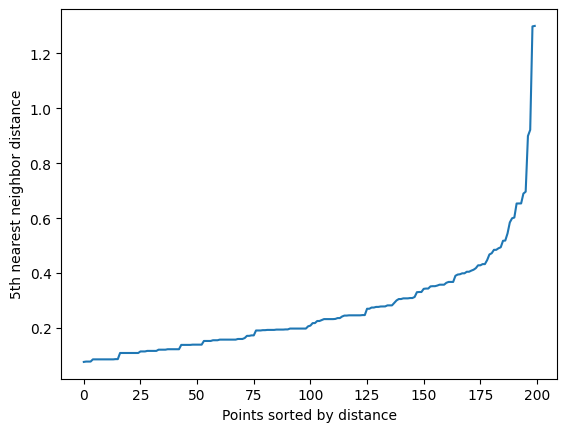

In [34]:
from sklearn.neighbors import NearestNeighbors
import numpy as np

neighbors = NearestNeighbors(n_neighbors=5).fit(mall[columns])

distances, _ = neighbors.kneighbors(mall[columns])

k_distances = np.sort(distances[:, 4])

plt.plot(k_distances)
plt.xlabel('Points sorted by distance')
plt.ylabel('5th nearest neighbor distance')
plt.show()


for eps i would chose about 0.4 because this is where it starts curving upward here. The elbow happens right around 0.4 based on the chart before going straight up toward the outliers in the right side. 

### (c) (5 points)

Fit DBSCAN with `min_samples = 5` and your chosen `eps`. Report the number of clusters found, the size of each cluster, and the number of observations labeled as noise. Then visualize the result with a scatter plot of the two variables, coloring the points by cluster label and showing noise points in a distinct color.

Estimated number of clusters: 3
Estimated number of noise points: 14
cluster 0: 142 points
cluster 1: 11 points
cluster 2: 33 points


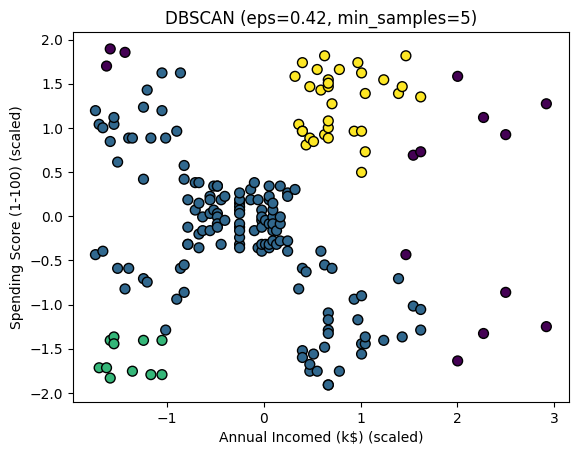

In [36]:
from sklearn.cluster import DBSCAN

eps = 0.42

dbscan = DBSCAN(eps=eps, min_samples=5)
labels = dbscan.fit_predict(mall[columns])

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("Estimated number of clusters:", n_clusters)
print("Estimated number of noise points:", n_noise)
for label in set(labels):
    if label != -1:
        print(f"cluster {label}: {(labels == label).sum()} points")

# The plot

plt.scatter(mall[columns].values[:, 0], mall[columns].values[:, 1], c=labels, cmap='viridis', edgecolor='k', s=50)
plt.title(f"DBSCAN (eps={eps}, min_samples=5)")
plt.xlabel("Annual Incomed (k$) (scaled)")
plt.ylabel("Spending Score (1-100) (scaled)")
plt.show()


### (d) (5 points)

Describe each cluster (average income and spending score) and the noise points. Then explain what happens to the number of clusters and the number of noise points if you (i) decrease `eps` or (ii) increase `min_samples`. Support your answer by trying at least two different settings. How does DBSCAN compare to $k$-means for this data?

In [37]:
# decrease eps

db1 = DBSCAN(eps=0.30, min_samples=5).fit(mall[columns])
print("Decreased eps to 0.30:")
print(f"Clusters: {len(set(db1.labels_)) - (1 if -1 in db1.labels_ else 0)} | Noise points: {list(db1.labels_).count(-1)}")

# Increase min_samples

db2 = DBSCAN(eps=0.42, min_samples=10).fit(mall[columns])
print("Increased min_samples to 10:")
print(f"Clusters: {len(set(db2.labels_)) - (1 if -1 in db2.labels_ else 0)} | Noise points: {list(db2.labels_).count(-1)}")



Decreased eps to 0.30:
Clusters: 7 | Noise points: 35
Increased min_samples to 10:
Clusters: 4 | Noise points: 46


The clusters show customer groups by income and spending patterns while the noise points show the isolated outliers.DBSCAN discovers shapes and isolates noise. In this case when you decreased the eps it shrinks the neighborhood which makes it harder for points to count as neighbors and causes dense clusters to go into more culster pieces. When you increase the min_samples it raises the density requirement for a cluster. The smaller groups cant form clusters and are labeled as noise which then just drops the cluster count.